In [1]:
# missing values
from pyexpat import model
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import yaml
from pathlib import Path
import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns
from random import shuffle
from sklearn.utils import shuffle




# from config import load_config


In [2]:
def load_config(data_path):
    config_path = Path("../config/configs.yaml")
    with config_path.open("r", encoding="utf-8") as config_file:
        config = yaml.safe_load(config_file)
        return config
def load_data(data_path):
    # target = df['Attrition']
    df = pd.read_csv(data_path)
    return df
if __name__== "__main__":
    df = load_data("../data/raw_dataset.csv")
    print(df.info())
    


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

The total dataset has 35 columns



print(df.info())


In [3]:
def check_data(df):
    """Check missing and duplicated values"""
    return df.isnull().any().any() and df.duplicated().any()

if __name__== "__main__":
    data = load_data("../data/raw_dataset.csv")
    df = check_data(data)
    print(df)

False


In [4]:
if __name__== "__main__":
    data = load_data("../data/raw_dataset.csv")
    # df = data[["EmployeeCount", "EmployeeNumber", "StandardHours"]]
    print(data.columns)

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')


In [5]:
if __name__== "__main__":
    data = load_data("../data/raw_dataset.csv")
    # df = data[["EmployeeCount", "EmployeeNumber", "StandardHours"]]
    print(data[['MonthlyIncome','HourlyRate','MonthlyRate']].value_counts())

MonthlyIncome  HourlyRate  MonthlyRate
19999          65          5678           1
1009           32          26999          1
1051           73          13493          1
1052           74          23384          1
1081           89          16019          1
                                         ..
1483           79          16102          1
1420           54          25233          1
1416           36          17258          1
1393           95          24852          1
1359           50          16154          1
Name: count, Length: 1470, dtype: int64


In [6]:
def num_columns(df):
    numeric = df.select_dtypes(include=['number']).columns
    return numeric
if __name__== "__main__":
    df = load_data("../data/raw_dataset.csv")
    # necc_col = drop_unnecessary_columns(df)
    numeric_columns = num_columns(df)
    print(numeric_columns)

Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome',
       'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
       'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')


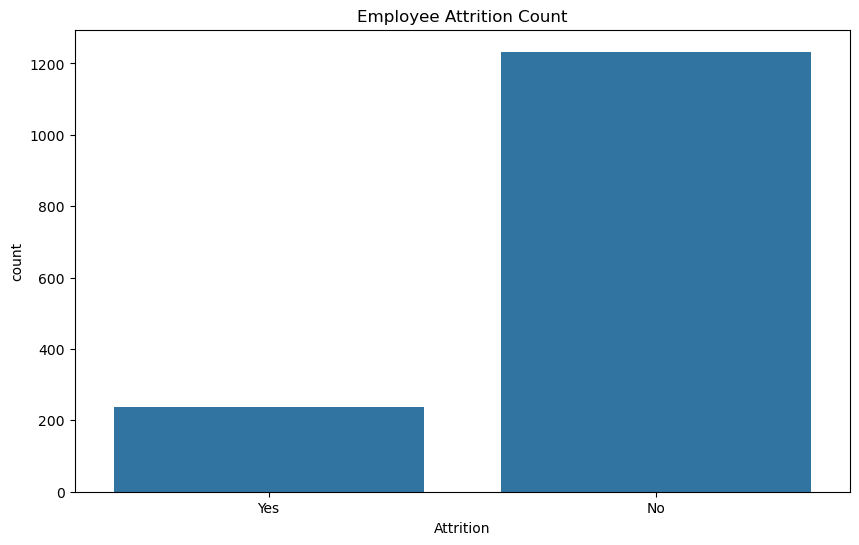

In [7]:
def plot(df):

    plt.figure(figsize=(10, 6))
    sns.countplot(x='Attrition', data=df)
    plt.title('Employee Attrition Count')
    plt.show()
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    plot(df)

Target is imbalanced

Data Visualization Employee Attrition 

In [8]:
def encoding_columnns(df):
    """Encode categorical columns using one-hot encoding."""
    categorical_cols = df.select_dtypes(include=['object']).columns
    df_encoded = pd.get_dummies(df, columns=categorical_cols, 
                                drop_first=True, 
                                dtype=int)
    return df_encoded
if __name__== "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
   
    print(df_encoded['Attrition_Yes'])

0       1
1       0
2       1
3       0
4       0
       ..
1465    0
1466    0
1467    0
1468    0
1469    0
Name: Attrition_Yes, Length: 1470, dtype: int64


In [9]:
def check_obj(df_encoded):
    object_cols = df_encoded.select_dtypes(include=['object']).columns
    print(object_cols)
    
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    check_obj(df_encoded)

Index([], dtype='object')


In [10]:
def corr(df_encoded):
    ah_corr = df_encoded.corr()['Attrition_Yes']
    return ah_corr
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    ah_corr = corr(df_encoded)
    print(ah_corr.sort_values(ascending=False))
        # df = data[["EmployeeCount", "EmployeeNumber", "StandardHours"]]



Attrition_Yes                        1.000000
OverTime_Yes                         0.246118
MaritalStatus_Single                 0.175419
JobRole_Sales Representative         0.157234
BusinessTravel_Travel_Frequently     0.115143
JobRole_Laboratory Technician        0.098290
Department_Sales                     0.080855
DistanceFromHome                     0.077924
EducationField_Technical Degree      0.069355
EducationField_Marketing             0.055781
NumCompaniesWorked                   0.043494
JobRole_Human Resources              0.036215
Gender_Male                          0.029453
JobRole_Sales Executive              0.019774
MonthlyRate                          0.015170
PerformanceRating                    0.002889
JobRole_Research Scientist          -0.000360
HourlyRate                          -0.006846
EmployeeNumber                      -0.010577
PercentSalaryHike                   -0.013478
EducationField_Other                -0.017898
Education                         

In [11]:
def clean_df(df_encoded):
    df_encoded = df_encoded.drop(columns=["EmployeeCount", "StandardHours"])
    return df_encoded
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)
    

The correlation function shows that columns (EmployeeCount, and StandardHours) are not correlated to target column at all. We will drop these columns

In [13]:
def splitting_data(df_cleaned, test_size=None, random_state=None):
    """
    Split the input DataFrame into training and validation data.
    Returns:
    Training and validation features and targets.
    """
    if df_cleaned is None:
        raise ValueError("DataFrame is None. Please provide a valid DataFrame.")
    config = load_config("configs/config.yaml")
    if test_size is None:
        test_size = config["test_size"]
    if random_state is None:
        random_state = config["random_state"]
    target = df_cleaned['Attrition_Yes']
    features = df_cleaned.drop('Attrition_Yes', axis=1)
    x_temp,x_test, y_temp,y_test = train_test_split(features, target, test_size=test_size, random_state=random_state)
    x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.25)

    return x_train, x_val, x_test, y_train, y_val, y_test  
if __name__== "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)
    split_data = splitting_data(df_cleaned)
    x_train, x_val, x_test, y_train, y_val, y_test = split_data
    print(x_train.shape, x_val.shape, x_test.shape, y_train.shape, y_val.shape, y_test.shape)
    # print(split_data)

(882, 45) (294, 45) (294, 45) (882,) (294,) (294,)


In [14]:
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)

    features_upsampled, target_upsampled = shuffle(
        features_upsampled, target_upsampled
    )

    return features_upsampled, target_upsampled


if __name__ == "__main__":
    features_upsampled, target_upsampled = upsample(
        x_train, y_train, 10
    )

In [15]:
def tuning_with_grid_search(features_upsampled, target_upsampled, x_val, y_val):
    best_f1 = 0
    best_model = None   
    best_params = {}
    param_grid = {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [5, 10, 20, 30, None],
        'min_samples_split': [2, 5, 10, 15],
        'bootstrap': [True, False],
        'class_weight': [None, 'balanced']
    }
    for n_estimators in param_grid['n_estimators']:
        for max_depth in param_grid['max_depth']:
            for min_samples_split in param_grid['min_samples_split']:
                for bootstrap in param_grid['bootstrap']:
                    for class_weight in param_grid['class_weight']:
                        model = RandomForestClassifier(
                            n_estimators=n_estimators,
                            max_depth=max_depth,
                            min_samples_split=min_samples_split,
                            bootstrap=bootstrap,
                            class_weight=class_weight,
                            random_state=42
                        )
                        model.fit(features_upsampled, target_upsampled)
                        y_pred = model.predict(x_val)
                        f1 = f1_score(y_val, y_pred)
                        if f1 > best_f1:
                            best_f1 = f1
                            best_model = model
                            best_params = {
                                'n_estimators': n_estimators,
                                'max_depth': max_depth,
                                'min_samples_split': min_samples_split,
                                'bootstrap': bootstrap,
                                'class_weight': class_weight
                            }
                            print(f"New best model found: F1 = {best_f1}, Params = {best_params}")
    return best_model, best_params, best_f1
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)
    x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_cleaned)
    upsampled_x_train, upsampled_y_train = upsample(x_train, y_train, 10)
    best_model, best_params, best_f1 = tuning_with_grid_search(upsampled_x_train, upsampled_y_train, x_val, y_val)
    print(f"Best model: F1 = {best_f1}, Params = {best_params}")
                    

New best model found: F1 = 0.38341968911917096, Params = {'n_estimators': 100, 'max_depth': 5, 'min_samples_split': 2, 'bootstrap': True, 'class_weight': None}
New best model found: F1 = 0.49557522123893805, Params = {'n_estimators': 100, 'max_depth': 5, 'min_samples_split': 2, 'bootstrap': True, 'class_weight': 'balanced'}
New best model found: F1 = 0.5048543689320388, Params = {'n_estimators': 100, 'max_depth': 5, 'min_samples_split': 2, 'bootstrap': False, 'class_weight': 'balanced'}
New best model found: F1 = 0.509090909090909, Params = {'n_estimators': 100, 'max_depth': 5, 'min_samples_split': 10, 'bootstrap': True, 'class_weight': 'balanced'}
New best model found: F1 = 0.5178571428571429, Params = {'n_estimators': 100, 'max_depth': 5, 'min_samples_split': 15, 'bootstrap': True, 'class_weight': 'balanced'}
New best model found: F1 = 0.5373134328358209, Params = {'n_estimators': 100, 'max_depth': 10, 'min_samples_split': 2, 'bootstrap': True, 'class_weight': 'balanced'}
New best mo

In [16]:
def model_training(features_upsampled, target_upsampled):
    config = load_config("configs/config.yaml")
    model = RandomForestClassifier(
        n_estimators=100,      # Number of trees (more = better, but slower)
        max_depth=5,          # Individual tree depth
        min_samples_split=15,   # Tree splitting criteria
        bootstrap=False,        # Sample with replacement
        random_state=42,
        class_weight='balanced')  # Replace SomeModel with the actual model you want to use
    model.fit(features_upsampled, target_upsampled)
    return model
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)   
    x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_cleaned)
    upsampled_features, upsampled_target = upsample(x_train, y_train, 10)
    model = model_training(upsampled_features, upsampled_target)
    print(model)
    predicted_val = model.predict(x_val)
    print('F1 on validation set:', f1_score(y_val, predicted_val))
    predicted_test = model.predict(x_test)
    print('F1 on test set:', f1_score(y_test, predicted_test))


RandomForestClassifier(bootstrap=False, class_weight='balanced', max_depth=5,
                       min_samples_split=15, random_state=42)
F1 on validation set: 0.5230769230769231
F1 on test set: 0.37209302325581395


In [17]:
def predict(model, x_test, y_test):
    # Make predictions on the test set
    predictions = model.predict(x_test)
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")
    return predictions

if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)
    x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_cleaned)
    model = model_training(x_train, y_train)
    predictions = predict(model, x_test, y_test)
    cm = confusion_matrix(y_test, predictions)
    print(f"Confusion Matrix:\n{cm}")

Accuracy: 0.7891156462585034
Precision: 0.27450980392156865
Recall: 0.358974358974359
F1 Score: 0.3111111111111111
Confusion Matrix:
[[218  37]
 [ 25  14]]


In [21]:
f1 = f1_score(y_val, y_pred, pos_label=1)
print(f"F1 Score: {f1}")    

F1 Score: 0.0625


In [26]:
if 'Attrition_Yes' in x_train.columns:
    print("The column exists!")
else:
    print("The column does not exist!")

The column does not exist!


In [22]:
print(y_train.unique())  # should include 0 and 1

[0 1]


In [18]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
)

y_pred = best_model.predict(x_test)
y_score = best_model.predict_proba(x_test)[:, 1]

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("PR-AUC (average precision):", average_precision_score(y_test, y_score))

              precision    recall  f1-score   support

           0       0.89      0.96      0.92       255
           1       0.44      0.21      0.28        39

    accuracy                           0.86       294
   macro avg       0.67      0.58      0.60       294
weighted avg       0.83      0.86      0.84       294

Confusion matrix:
 [[245  10]
 [ 31   8]]
PR-AUC (average precision): 0.38030829901594165


In [19]:
def feature_importance(model, x_train):
    model = model.fit(x_train, y_train)
    importances = model.feature_importances_
    feature_names = x_train.columns
    feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
    })
    feature_importance_df = feature_importance_df.sort_values('importance', ascending=False)
    print(feature_importance_df)
if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)   
    x_train, x_val, x_test, y_train, y_val, y_test  = splitting_data(df_cleaned)
    model = model_training(x_train, y_train)
    feature_importance(model, x_train)

                              feature  importance
44                       OverTime_Yes    0.127070
8                            JobLevel    0.089613
10                      MonthlyIncome    0.074776
16                   StockOptionLevel    0.073989
20                     YearsAtCompany    0.072446
0                                 Age    0.050649
17                  TotalWorkingYears    0.047576
23               YearsWithCurrManager    0.046281
21                 YearsInCurrentRole    0.040710
43               MaritalStatus_Single    0.037357
12                 NumCompaniesWorked    0.029160
4                      EmployeeNumber    0.023980
11                        MonthlyRate    0.022245
6                          HourlyRate    0.020339
2                    DistanceFromHome    0.019089
1                           DailyRate    0.018937
22            YearsSinceLastPromotion    0.015898
26  Department_Research & Development    0.015101
41       JobRole_Sales Representative    0.014702


Age                -0.159205
DailyRate          -0.056652
DistanceFromHome    0.077924
Education          -0.031373
EmployeeNumber     -0.010577
Name: Attrition_Yes, dtype: float64


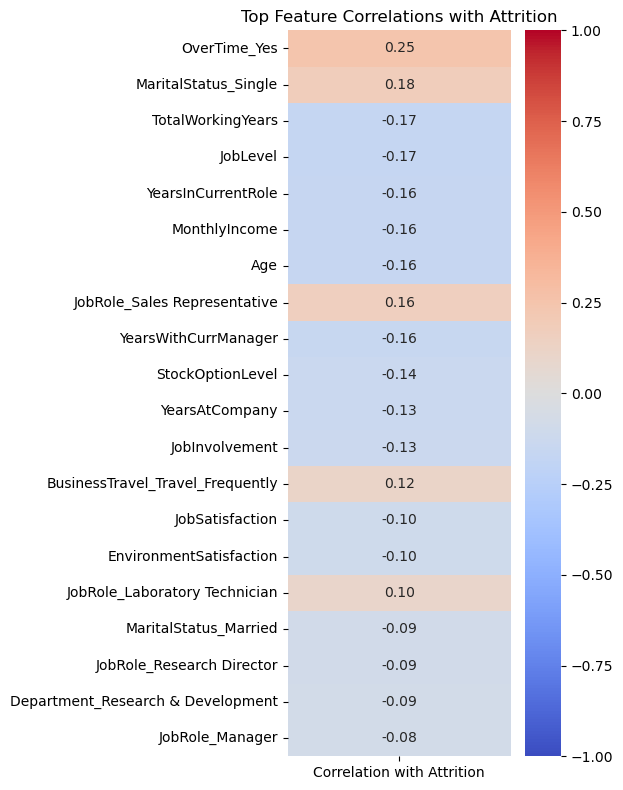

In [42]:
def corr_matrix(df_clean):
    corr = df_clean.corr(numeric_only=True)["Attrition_Yes"]
    corr = corr.drop("Attrition_Yes")
    print(corr.head())

    # Select the strongest correlations by magnitude, keeping their signs.
    top_corr = corr.loc[corr.abs().sort_values(ascending=False).head(20).index]

    plt.figure(figsize=(6, max(4, len(top_corr) * 0.4)))
    sns.heatmap(
        top_corr.to_frame(name="Correlation with Attrition"),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
    )
    plt.title("Top Feature Correlations with Attrition")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    df = load_data("../data/raw_dataset.csv")
    df_encoded = encoding_columnns(df)
    df_cleaned = clean_df(df_encoded)
    corr_matrix(df_cleaned)